## 2D модель распределения кривых и оптимизации через градиентный спуск

**Information:** 
    *Это продвинутая версия программы, добавлен новый новый параметр оптимзации - высота. 
    

### 0. Настройки

In [1]:
# Настройка проекта
import matplotlib.pyplot as plt
import meep as mp
import conf
import torch
from lib import adjoint as mpa
from lib import torch_functions as tf
from lib import numpy_functions as nf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
from autograd import numpy as npa
import numpy as np
mp.verbosity(0) # decrease amount of output

1

In [2]:
"""
Ниже базовая целевая ф-ия, которая хорошо работает для одного угла. Но пенальти на несколько углов накладываются не корректно.
"""

def J(FF):
    """
    FF: массив формы (n_points, n_waves, n_fields). 
    penalty_coef: коэффициент штрафа (подбирается эмпирически).
    """
    # вычисляем по‑точечную интенсивность: shape = (n_points, n_waves)
    I = npa.abs(FF[0, :, 2])**2 / mean_IPlane_angle_stack[global_index_angle] / max_IAiry_in_angle_stack[global_index_angle]

    # базовая цель — среднее по волнам
    J_base = npa.mean(I)
    
    # штраф за разброс между волнами (variance или std^2)
    penalty = penalty_coef * (npa.std(I))**2    # либо λ * (np.std(f_w))**2

    return J_base - penalty

class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):

        # Forward pass for both single- and multi-frequency optimization.
        # Unwraps torch tensors to numpy arrays, calls external opt(), and saves gradients.

        rho_list = []
        shapes = []
        # Extract data and shapes
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            # if extra leading dim, squeeze it
            if arr.ndim > 1 and arr.shape[0] == 1:
                arr = arr.squeeze(0)
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())

        # Call external optimizer: returns objective and gradients
        f0, grad_rho = opt(rho_list)

        # Save context for backward
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype
        
        # print(f"shapes len = {len(shapes)}")
        # print("shapes:", ctx.shapes)
        # print("returned grad shapes:", [g.shape for g in ctx.grad_rho])
        missing = set(range(len(ctx.shapes))) - set(range(len(ctx.grad_rho)))
        print("Missing gradient indices:", missing)

        # Return scalar objective as torch tensor
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):

        # Backward pass: reshape and convert numpy gradients to torch,
        # handling both single- and multi-frequency cases.

        grads = []
        for g_np, shape in zip(ctx.grad_rho, ctx.shapes):
            # For multi-frequency, collapse along freq axis
            if g_np.ndim == 2:
                # average gradients over frequencies
                g_arr = np.mean(g_np, axis=1).reshape(shape)
            else:
                # single-frequency gradient
                g_arr = np.asarray(g_np, dtype=np.float64).reshape(shape)

            # Convert to torch tensor and scale by upstream grad_output
            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)
    
        # 2) добавляем нули для «потерянных» входов
        n_missing = len(ctx.shapes) - len(grads)
        if n_missing > 0:
            for idx in range(n_missing):
                shape = ctx.shapes[len(grads) + idx]
                zero = torch.zeros(shape, device=ctx.device, dtype=ctx.dtype)
                grads.append(zero)
            
        # Return gradient for each input
        return tuple(grads)

# Convenience wrapper
def opt_torch(*x_tensors):

    # Apply the OptFunction in a torch-friendly way.
    return OptFunction.apply(*x_tensors)


# =============================================

# LOCAL

# Функция запуска локальной ячейки
def init_loc_opt(index_angle, loc_orders, obj_func, a_initial, h_initial, is_plot=False):
    
    global global_index_angle
    global_index_angle = index_angle
    
    if index_angle == 0:
        extended_loc_orders = int(loc_orders / 2)
        is_global = True
        first_index = 0
        loc_symmetry = [mp.Mirror(mp.Y)]
    else:
        extended_loc_orders = loc_orders - 1
        is_global = False
        first_index = 1
        loc_symmetry = None
        
    print(f"extended_loc_orders: {extended_loc_orders}")
    print(f"loc_symmetry: {loc_symmetry}")
    
    loc_a_params = torch.full((extended_loc_orders,), a_initial, dtype=torch.float64)
    loc_h_params = torch.full((extended_loc_orders,), h_initial, dtype=torch.float64)
    
    loc_d_rt_np, loc_mid_rt_np = nf.get_drt_midrt(rt_np, extended_loc_orders, is_global = is_global)
    loc_rt_tf = tf.calculate_radii_step(D=conf.diaphragm, orders=extended_loc_orders)
    
    loc_focus_point_list = []       
    point1 = mp.Vector3(x = conf.f, y = 0)
    loc_focus_point_list.append(point1)
    
    loc_design_region = []
    list_loc_x0 = tf.material_grid_weight_2d(loc_a_params, loc_h_params, conf.at_hei, extended_loc_orders, conf.stack, loc_rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = False, beta = 50.0, plot = False)

    geometry = [mp.Block(
        material=conf.in_material,
        size=mp.Vector3(conf.in_sub, mp.inf, 0),
        center=mp.Vector3(conf.sub_center.x),
    )]
    

    for loc_order in range(first_index, extended_loc_orders):
        weight_numpy = list_loc_x0[loc_order].detach().cpu().numpy() # тут вытаскиваем значения для первичной инициализации и для визуальной проверки
        res = resolutions_objs[loc_order]
        material_grid = mp.MaterialGrid(
            mp.Vector3(x=res.h, y=res.w),
            mp.air,
            conf.at_material,
            weights=weight_numpy
        )
        loc_design_region.append(mpa.DesignRegion(
            material_grid,
            volume=mp.Volume(center=mp.Vector3(x = conf.at_hei/2, y=loc_mid_rt_np[loc_order]), size=mp.Vector3(x=conf.at_hei, y=loc_d_rt_np[loc_order]- 0.1)) # 0.1 небольшое смещение от края геометрии чтобы порядки не наехали друг на друга
        ))
        
        geometry.append(mp.Block(
            size=mp.Vector3(x=conf.at_hei, y=loc_d_rt_np[loc_order]),
            center=mp.Vector3(x=conf.at_hei/2, y=loc_mid_rt_np[loc_order]),
            material=material_grid,
        ))

        
    loc_sim = mp.Simulation(
        cell_size=loc_cell,
        boundary_layers=[mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)],
        geometry=geometry,
        sources=stack_batch_src[index_angle],
        default_material=mp.Medium(index=1.0),
        resolution= sim_resolution,
        symmetries = loc_symmetry,
    )
    
    FarFields = mpa.Near2FarFields(loc_sim, [locNearRegion], loc_focus_point_list)
    ob_list = [FarFields]
    
    loc_opt = mpa.OptimizationProblem(
        simulation=loc_sim,
        objective_functions=[obj_func],
        objective_arguments=ob_list, # ready 
        design_regions=loc_design_region, # ready 
        frequencies=conf.inc_frequents_array, # ready
        maximum_run_time= conf.maximum_run_time,
        until_steps=conf.maximum_run_time,
    )
    
    if is_plot:
        plt.figure(figsize=(5, 100))
        loc_opt.plot2D(True)
    
    return loc_opt

def init_loc_opt_hyper(index_angle, loc_orders, a_initial, h_initial, p_min, p_max, lr):
    if index_angle == 0:
        extended_loc_orders = int(loc_orders / 2)
    else:
        extended_loc_orders = loc_orders - 1

    # --- a_initial ---
    if isinstance(a_initial, (float, int)):
        loc_a_params = torch.full((extended_loc_orders,), a_initial, dtype=torch.float64)
    elif isinstance(a_initial, torch.Tensor):
        loc_a_params = a_initial
    else:
        raise TypeError("a_initial must be float, int, or torch.Tensor")

    # --- h_initial ---
    if isinstance(h_initial, (float, int)):
        loc_h_params = torch.full((extended_loc_orders,), h_initial, dtype=torch.float64)
    elif isinstance(h_initial, torch.Tensor):
        loc_h_params = h_initial
    else:
        raise TypeError("h_initial must be float, int, or torch.Tensor")

    # 1) нормируем в [0,1] и инвертируем sigmoid
    loc_u_a0 = torch.log((loc_a_params - p_min) / (p_max - loc_a_params))
    loc_u_h0 = torch.log((loc_h_params - h_min) / (h_max - loc_h_params))
    

    # 2) делаем параметры оптимизируемыми
    loc_u_a = torch.nn.Parameter(loc_u_a0)
    loc_u_h = torch.nn.Parameter(loc_u_h0)
    loc_optimizer = torch.optim.Adam(
        [loc_u_a, loc_u_h],
        lr=lr,
        betas=(0.95, 0.999)  # TODO: разобраться в значении betas
    )

    # 4.1 История
    store_loc_history = {
        'f0': [],
        'grad_norm': [],
        'loc_a_params': [],
        'loc_h_params': [],
        'beta': []
    }

    return loc_optimizer, store_loc_history, loc_u_a, loc_u_h

def run_loc_opt(index_angle, loc_orders, loc_optimizer, loc_u_a, loc_u_h, loc_history, beta):
    if index_angle == 0:
        extended_loc_orders = int(loc_orders / 2)
    else:
        extended_loc_orders = loc_orders-1
    
    loc_rt_tf = tf.calculate_radii_step(D=conf.diaphragm, orders=extended_loc_orders)
    best_f0 = -float('inf')  # лучшее значение f0, с которого ведём отсчёт
    wait = 0    
    
    for step in range(1, num_steps + 1):
        loc_optimizer.zero_grad()
        
        # 5.1. Декодируем параметры
        a_params = decoder_a(loc_u_a)
        h_params = decoder_h(loc_u_h)
        
        # 5.1. Получаем распределение epsilon
        # x — тензор размера (Nx_resolution, 1)
        x_list = tf.material_grid_weight_2d(a_params, h_params,  conf.at_hei, extended_loc_orders, conf.stack, loc_rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = True, beta = beta, plot = False)
    
        # 5.2. Вычисляем функцию и её градиент через meep.adjoint.opt
        # opt ожидает список тензоров x, возвращает скаляр f0 и список градиентов [grad_x]   
        value = opt_torch(*x_list) # возвращает тензор-скаляр
    
        # 5.3. Переносим градиент на params через цепное правило:
        #      dx/dparams нам даёт get_weights.backward(), поэтому
        #      мы просто вызываем .backward() от -f0 (максимизируем f0)
        loss = -value
        loss.backward()
        
    
        # 5.4. Норма градиента для логирования
        grad_norm = 0.0
        for param in (loc_u_a, loc_u_h):
            grad_norm += param.grad.detach().norm().item()**2
        grad_norm = grad_norm**0.5
        
        # 5.5. Шаг оптимизатора
        loc_optimizer.step()
    
        # 5.6. Увеличение beta для "закалки" бинарных масок
        beta = min(15.0, beta * 1.1)
    
        # 5.8. Сохраняем историю
        loc_history['f0'].append(value.item())
        loc_history['grad_norm'].append(grad_norm)
        loc_history['loc_a_params'].append(a_params.detach().cpu().clone())
        loc_history['loc_h_params'].append(h_params.detach().cpu().clone())
        loc_history['beta'].append(beta)
    
        
        # 5.10. Логируем
        if step % 1 == 0 or step == 1:
            print(f"Step {step:3d} | f0 = {value.item()} | beta = {beta} ||grad|| = {grad_norm} || lr = {loc_optimizer.param_groups[0]['lr']} || wait = {wait}")
        if (loc_u_a.all() or loc_u_a.all()) is None:
            print("Stopping optimization")
            break
        # --- ранняя остановка ---
        if value > best_f0 + threshold:
            best_f0 = value
            wait = 0
        else:
            wait += 1
        # --- ранняя остановка ---
    
        if wait >= patience:
            print(f"Early stopping at step {step}: "
                  f"f0 hasn't improved by >{threshold} for {patience} steps")
            break
            
    # 6. По окончании params содержит оптимальное приближение
    best_idx = max(range(len(loc_history['f0'])), key=lambda i: loc_history['f0'][i])
    best_a_params = loc_history['loc_a_params'][best_idx]
    best_h_params = loc_history['loc_h_params'][best_idx]
    print(f"\nBest f0 = {loc_history['f0'][best_idx]} at step {best_idx+1}")
        
    return loc_history, best_a_params, best_h_params

def viz_loc_opt(index_angle, loc_history, best_a_params, best_h_params,loc_orders, is_save = True):
    if index_angle == 0:
        extended_loc_orders = int(loc_orders / 2)
    
    else:
        extended_loc_orders = loc_orders-1
    
    # Построение графиков
    plt.figure(figsize=(10, 5))
    plt.plot(loc_history['f0'], label='f0')
    plt.xlabel('Epoch')
    plt.ylabel('Value f0')
    plt.title('Optimisation progress')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # 7. Строим график params
    idx = torch.arange(extended_loc_orders, dtype=torch.float32)
    plt.figure(figsize=(6, 4))
    plt.plot(idx.numpy(), best_a_params, marker='o')
    plt.plot(idx.numpy(), best_h_params, marker='+')
    plt.title('Optimized params')
    plt.xlabel('Order')
    plt.ylabel('Params')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    if is_save:
        help_functions.save_params(params = best_a_params, name = "best_a")
        help_functions.save_params(params = best_h_params, name = "best_h")

def test_loc(
    index_angle: int,
    loc_orders: int,
    source: object,
    best_a_params: torch.Tensor = None,
    best_h_params: torch.Tensor = None,
    is_plot_sim: bool = False,
    is_load_name_a: str = None,
    is_load_name_h: str = None,
) -> np.ndarray:
    """
    Выполняет локальную FDTD-симуляцию для заданного угла и параметров оптимизации.

    Если is_load=True, параметры лучшей модели (best_a_params и best_h_params) загружаются
    из файлов "best_a.pt" и "best_h.pt" соответственно, и передаваемые в функцию аргументы
    игнорируются.

    Parameters:
    -----------
    index_angle : int
        Индекс угла выхода луча (0 … N-1).
    loc_orders : int
        Число локальных порядков оптимизации.
    best_a_params : torch.Tensor, optional
        Параметры A оптимизации (необязательны, если is_load=True).
    best_h_params : torch.Tensor, optional
        Параметры H оптимизации (необязательны, если is_load=True).
    is_load : bool
        Флаг, указывающий, загружать ли параметры из файлов вместо использования переданных.

    Raises:
    -------
    ValueError
        Если is_load=False и один из best_* параметров не передан.

    Returns:
    --------
    None
    """
    # Загрузка параметров из файлов
    if (is_load_name_a != None) and (is_load_name_h != None):
        best_a_params = torch.load(is_load_name_a, weights_only=True)
        best_h_params = torch.load(is_load_name_h, weights_only=True)

    # Вычисляем дополнительные атрибуты симметрии и диапазона порядков
    if index_angle == 0:
        extended_loc_orders = loc_orders // 2
        is_global = True
        first_index = 0
        loc_symmetry = [mp.Mirror(mp.Y)]
    else:
        extended_loc_orders = loc_orders - 1
        is_global = False
        first_index = 1
        loc_symmetry = None

    # IPlane_base, _ = nf.get_Ibase_simulation(
    #     monitor=locNearRegion,
    #     sources=source,
    #     cell=loc_cell,
    #     frequents_array=conf.inc_frequents_array,
    #     max_run_time=conf.maximum_run_time,
    #     symmetries=loc_symmetry,
    # )

    # Радиусные шаги и области дизайна
    loc_rt_tf        = tf.calculate_radii_step(D=conf.diaphragm, orders=extended_loc_orders)
    loc_d_rt_np, loc_mid_rt_np = nf.get_drt_midrt(rt_np, extended_loc_orders, is_global=is_global)
    loc_design_region = []

    # Генерация веса на сетке
    x_test = tf.material_grid_weight_2d(
        best_a_params, best_h_params,
        conf.at_hei, extended_loc_orders,
        conf.stack, loc_rt_tf,
        resolutions_tuples,
        Q=conf.Q, w=conf.w,
        LIMIT_SHAPE=conf.LIMIT_SHAPE,
        smooth=False, beta=50, plot=False
    )

    # Базовая геометрия подложки
    geometry = [
        mp.Block(
            material=conf.in_material,
            size=mp.Vector3(conf.in_sub, mp.inf, 0),
            center=mp.Vector3(conf.sub_center.x)
        )
    ]

    # Добавляем слои дизайна по локальным порядкам
    for loc_order in range(first_index, extended_loc_orders):
        weight_np     = x_test[loc_order].detach().cpu().numpy()
        res           = resolutions_objs[loc_order]
        material_grid = mp.MaterialGrid(
            mp.Vector3(x=res.h, y=res.w),
            mp.air, conf.at_material,
            weights=weight_np
        )
        loc_design_region.append(
            mpa.DesignRegion(
                material_grid,
                volume=mp.Volume(
                    center=mp.Vector3(x=conf.at_hei/2, y=loc_mid_rt_np[loc_order]),
                    size=  mp.Vector3(x=conf.at_hei, y=loc_d_rt_np[loc_order] - 0.1)
                )
            )
        )
        geometry.append(
            mp.Block(
                size=   mp.Vector3(x=conf.at_hei, y=loc_d_rt_np[loc_order]),
                center= mp.Vector3(x=conf.at_hei/2, y=loc_mid_rt_np[loc_order]),
                material=material_grid
            )
        )

    # Настройка симуляции
    loc_sim = mp.Simulation(
        cell_size=loc_cell,
        boundary_layers=[mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)],
        geometry=geometry,
        sources=source,
        default_material=mp.Medium(index=1.0),
        resolution=sim_resolution,
        symmetries=loc_symmetry
    )

    # Добавление near2far-мониторов
    near2far_regions = []
    for freq in conf.inc_frequents_array:
        near2far_regions.append(
            loc_sim.add_near2far(
                freq,           # центральная частота
                conf.inc_df,    # ширина спектра
                1,              # дискретность
                locNearRegion
            )
        )

    # Запуск симуляции
    loc_sim.run(until=conf.maximum_run_time)

    # Визуализация поля
    if is_plot_sim:
        plt.figure(figsize=(2, 50))
        loc_sim.plot2D(
            fields=mp.Ez,
            output_plane=mp.Volume(center=mp.Vector3(0, 0), size=loc_cell)
        )
        plt.show()

    # Нормировка и вычисление интенсивности
    if index_angle == 0: shift = 0
    else : shift = conf.main_source_center.x - conf.flux_center.x
    
    IOptimized     = nf.get_I_loc(loc_sim, near2far_regions, shift, conf.ff_res, mp.Vector3(0, conf.spot_ff, 0), f=conf.f)

    return IOptimized    

def update_global_params(
    index_angle: int,
    global_a_params: torch.Tensor,
    global_h_params: torch.Tensor,
    loc_best_a_params: torch.Tensor,
    loc_best_h_params: torch.Tensor,
    is_save: bool
) -> None:
    """
    Перезаписывает диапазон элементов в глобальных тензорах torch.float64
    локальными лучшими тензорами, подгоняя диапазон под длину локальных данных.

    Параметры:
    -----------
    global_a_params : torch.Tensor, shape (N,), dtype=torch.float64
    global_h_params : torch.Tensor, shape (N,), dtype=torch.float64
    loc_best_a_params : torch.Tensor, shape (M,), dtype=torch.float64
    loc_best_h_params : torch.Tensor, shape (M,), dtype=torch.float64
    index_angle : Any
        Аргумент для nf.get_indx_orders, возвращающего (indx_start, indx_end).
    nf : объект
        С методом get_indx_orders(angle) → Tuple[int, int].
    """
    # 1. Получаем начальный и конечный индексы
    indx_start, indx_end = nf.get_indx_orders(index_angle)
    indx_start = int(indx_start)
    indx_end = int(indx_end)
    actual_len = loc_best_a_params.numel()

    # 2. Подгоняем конец диапазона на разницу между локальной и текущей длиной
    diff = actual_len - (indx_end - indx_start)
    indx_end += diff

    # 3. Обрезаем по границам глобальных тензоров
    max_len = min(global_a_params.numel(), global_h_params.numel())
    indx_start = max(0, indx_start)
    indx_end = min(indx_end, max_len)

    # 4. Вычисляем реальное число копируемых элементов
    length_to_copy = min(indx_end - indx_start, actual_len)
    if length_to_copy <= 0:
        return

    # 5. Батчевое копирование
    global_a_params[indx_start:indx_start + length_to_copy] = loc_best_a_params[:length_to_copy]
    global_h_params[indx_start:indx_start + length_to_copy] = loc_best_h_params[:length_to_copy]
    
    if is_save:
        help_functions.save_params(global_a_params, name = "global_a_params" )
        help_functions.save_params(global_h_params, name = "global_h_params" )
    
def get_local_tensor_from_global(global_params, index_angle, loc_orders):
    """
    Извлекает участок из global_params в диапазоне индексов, определенных index_angle.
    Если конечный индекс выходит за пределы тензора, дополняет тензор значениями 1.0
    и выводит предупреждение.

    Args:
        global_params (torch.Tensor): Глобальный тензор параметров.
        index_angle: Угол, определяющий начальный и конечный индексы.

    Returns:
        torch.Tensor: Извлеченный тензор.
    """
    len_global = len(global_params)
    
    if index_angle == 0:
        # Получаем начальный и конечный индексы
        indx_start, indx_end = nf.get_indx_orders(index_angle)
    else:
        indx_start, _ = nf.get_indx_orders(index_angle)
        # Вычисляем конечный индекс
        indx_end = indx_start + loc_orders
    
    # Если достаточно элементов, извлекаем нужный участок
    if indx_end <= len_global:
        local_tensor = global_params[indx_start:indx_end]
    else:
        # Извлекаем все доступные элементы
        available = len_global - indx_start
        local_tensor = global_params[indx_start:len_global]
        # Создаем дополнение из единиц
        padding = torch.ones(indx_end - len_global, dtype=global_params.dtype)
        # Объединяем извлеченные элементы с дополнением
        local_tensor = torch.cat((local_tensor, padding))
        print(f"Last index ({indx_end}) over {len_global} of global index."
                      f" Added {indx_end - available} ones indexes")
    
    return local_tensor

## Основная программа
### 1.1 Предрасчет нормировки

Note:
   - коэффициент преломления среды для всего диапазона считаем одинаковым
   - инициализируем с углом наклона 0

In [3]:
"""
Base parameters
"""
# 1. Shape
global_index_angle = None
rt_tf = tf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
rt_np = nf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
d_rt_np, mid_rt_np = nf.get_drt_midrt(rt_np, conf.orders, is_global = True)

penalty_coef = 0.0

a_initial_params = 1.0
h_initial_params = 1.0

global_a_params = torch.full((conf.orders,), a_initial_params, dtype=torch.float64)
global_h_params = torch.full((conf.orders,), h_initial_params, dtype=torch.float64)

# 1.1 Cписок разрешений
gen_resolution = nf.AdaptiveResolution(
    drt=d_rt_np,
    x_dim=conf.x_dim,
    h_dim= conf.h_dim,
)
resolutions_objs = gen_resolution.generate()
resolutions_tuples = [(r.w, r.h) for r in resolutions_objs]
sim_resolution = conf.min_resolution * conf.coef_resolution

angle_in_rad = np.radians(conf.angle_list)
angle_in_deg = conf.angle_list
angle_after_refraction_in_radii = my_sources.refraction_input(angle_in_deg, conf.in_epsilon)
angle_after_refraction_in_deg = np.rad2deg(angle_after_refraction_in_radii)

# 2. Источники
# Полный набор источников для всех углов n_angels, которые мы будем вытаскивать по мере необходимости
    # src - это непрерывная плоская волна с одной длинной волны
    # batch - это группа непрерывных плоских волн с разными длинами волн под одним углом
    # stack - это группа с разными углами волны группы волн с разными длинами волн
    
stack_batch_src = []
for angle in angle_after_refraction_in_radii:
    src = my_sources.BatchEigenmodeSource(
        frequencies=conf.inc_frequents_array,
        resolution=sim_resolution,
        diaphragm=conf.diaphragm,
        center=mp.Vector3(x=conf.main_source_center.x, y = 0 ),
        angle_in_rad=angle,
        verbose=False,
    )
    batch_src = src.get_sources()
    stack_batch_src.append(batch_src)

# 3. Optimizer
num_steps = 50       # число итераций оптимизации
lr=0.2               # скорость обучения для Adam. Note: 0.1 - слишком мало (50 эпох), 0.25 - все еще мало (20-30 эпох), 0.5 - грубо (8-10 эпох). Слишком медленное обучение. 0.5 - наиболее универсальный параметр. Понижение lr c 0.3 до 0.2 минимум в 2 раза увеличивают количество иттераций оптимизации, но также немного повышает рузультат.
beta = 2.0          # параметр сглаживания для get_weights

    # 3.1 Инициализация параметров
p_min, p_max = 0.01, 30.0
h_min, h_max = 0.01, conf.at_hei

    # 3.2. заводим декодеры для обратного перехода в [p_min, p_max] и [h_min, h_max]
decoder_a = my_decoders.SigmoidDecoder(pmin=p_min, pmax=p_max)
decoder_h = my_decoders.SigmoidDecoder(pmin=h_min, pmax=h_max)

    # 3.3 Параметры ранней остановки
patience = 3             # число шагов без существенного улучшения
threshold = 0.0001       # минимальный прирост f0, считающийся значимым

# 4. Local
loc_cell = mp.Vector3(x = conf.cell_X, y = conf.diaphragm, z = 0) # ячейка
locNearRegion = mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(x = 0, y=loc_cell.y)) # монитор

# 5. Вывод параметров линзы
panel = my_gui.LiveInfoPanel()
panel.show()

# 6. Save and load
# "name" if you load, None if you save
# filename_focus_IAiry = "focus_Airy_simulation_D=500.0_f=500.0_diaph=500_res=10.npy"
# filename_base_IAiry = "base_Airy_simulation_D=500.0_f=500.0_diaph=500_res=10.npy"
# file_name_IBase = "base_IPlane_D=500.0_f=500.0_diaph=500_res=10.npy"
filename_focus_IAiry = "focus_Airy_simulation_D=2000.0_f=2000.0_diaph=2000_res=10.npy"
filename_base_IAiry = "base_Airy_simulation_D=2000.0_f=2000.0_diaph=2000_res=10.npy"
file_name_IBase = ""

len(rt) is 118
len(orders) is 118


HTML(value='\n        \n        <style>\n            .live-panel { \n                border: 2px solid #4CAF50…

In [4]:
IAiry_norm_scaled_in_angle_stack = []
max_IAiry_in_angle_stack = []
IPlane_base_angle_stack = []
mean_IPlane_angle_stack = []

In [5]:
IAiry, IBaseAiry, sim = nf.get_IAiry_norm_simulation(
    monitor =  locNearRegion, 
    cell = loc_cell, 
    filename_focus_airy = filename_focus_IAiry, 
    filename_base_airy= filename_base_IAiry, 
    resolution = sim_resolution,
    get_base=True,
    symmetries=[mp.Mirror(mp.Y)])

IAiry = IAiry[:,1:]
IBaseAiry = IBaseAiry[:,1:]

Data from focus_Airy_simulation_D=2000.0_f=2000.0_diaph=2000_res=10.npy loaded successfully.
Data from base_Airy_simulation_D=2000.0_f=2000.0_diaph=2000_res=10.npy loaded successfully.


In [6]:
airy_efficiency_p = IAiry.max(axis=0)/np.mean(IBaseAiry, axis = 0)
print(f"airy_efficiency_p: {airy_efficiency_p}")
airy_efficiency_r = nf.get_focusing_efficiency(IAiry/IAiry.max(axis = 0), spot_ff=conf.spot_ff, out_angle_in_deg=0, shift=0)
print(f"airy_efficiency_r: {airy_efficiency_r}")

airy_efficiency_p: [463.37229846 437.14661365 410.29077552 382.85855119]
airy_efficiency_r: [0.88386726 0.88544624 0.88421995 0.88395384]


In [ ]:
# nf.airy_characteristics()
# for i, (angle_rad, angle_deg) in enumerate(zip(angle_in_rad, angle_in_deg)):
#     IAiry_norm_in_angle = IAiry/IBaseAiry * np.cos(angle_rad)
#     max_IAiry_in_angle = IAiry_norm_in_angle.max(axis=0)
#     max_IAiry_in_angle_stack.append(max_IAiry_in_angle)
#     IAiry_norm_scaled_in_angle = IAiry_norm_in_angle / max_IAiry_in_angle
#     IAiry_norm_scaled_in_angle_stack.append(IAiry_norm_scaled_in_angle)
#     nf.get_plot_intensity(
#         conf.spot_ff,
#         IAiry_norm_scaled_in_angle,
#         out_angle_in_deg=angle_deg,
#         wavelength_array=conf.inc_wavelength_array,
#         shift=i * conf.diaphragm,
#         get_fwhm=True,
#     )

FWHM: 4.85 um , FWTM: 8.36 um, Airy diameter: 11.52 um


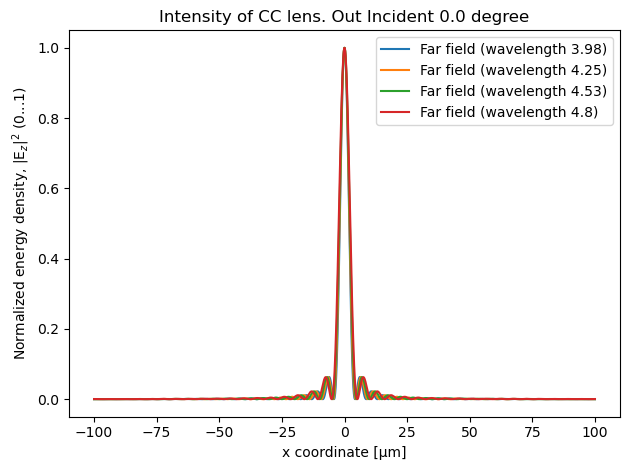

λ=3.98: FWHM = 3.90 µm
λ=4.25: FWHM = 4.10 µm
λ=4.53: FWHM = 4.30 µm
λ=4.8: FWHM = 4.70 µm


In [7]:
nf.airy_characteristics()
for i, (angle_rad, angle_deg) in enumerate(zip(angle_in_rad, angle_in_deg)):
    IAiry_norm_in_angle = IAiry * np.cos(angle_rad)
    max_IAiry_in_angle = IAiry_norm_in_angle.max(axis=0)
    max_IAiry_in_angle_stack.append(max_IAiry_in_angle)
    IAiry_norm_scaled_in_angle = IAiry_norm_in_angle / max_IAiry_in_angle
    IAiry_norm_scaled_in_angle_stack.append(IAiry_norm_scaled_in_angle)
    nf.get_plot_intensity(
        IAiry_norm_scaled_in_angle,
        out_angle_in_deg=angle_deg,
        wavelength_array=conf.inc_wavelength_array,
        shift=i * conf.diaphragm,
        isfwhm=True,
    )

In [9]:
# Ibase intensity
IPlane_base_angle_stack = nf.get_Ibase_batch_simulation(
    monitor =  locNearRegion,
    sources_batch=stack_batch_src, 
    cell=loc_cell, 
    frequents_array=conf.inc_frequents_array,
    filename= file_name_IBase, 
    symmetries = [mp.Mirror(mp.Y)])

mean_IPlane_angle_stack = np.mean(IPlane_base_angle_stack, axis=2)

Running simulation 1/1...


FloatProgress(value=0.0, description='0% done ', max=200.0)

Simulation result saved to: base_IPlane_D=500.0_f=500.0_diaph=500_res=10.npy


### 1.2 Инициализация оптимизатора

extended_loc_orders: 117
loc_symmetry: [<meep.simulation.Mirror object at 0x77f73d00dd30>]
len(rt) is 118
len(orders) is 117
Initialized global angle index 0
stage 0: Initializing DONE


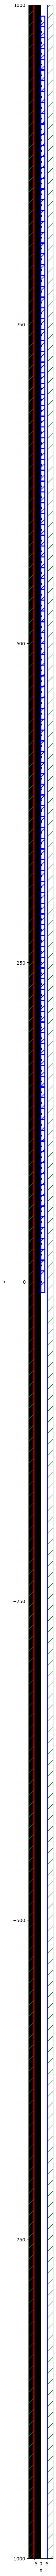

In [15]:
# ____ Singl 0 angle ____
opt_zone_start = 0
# Инициируем симмуляцию с оптимизатором
opt = init_loc_opt(opt_zone_start, conf.loc_orders, J, a_initial=a_initial_params, h_initial=h_initial_params, is_plot = True)
print(f"Initialized global angle index {global_index_angle}")
print(f"stage {opt_zone_start}: Initializing DONE")

Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

Starting adjoint run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step   1 | f0 = 0.038699688526634975 | beta = 2.2 ||grad|| = 0.054536192473464126 || lr = 0.2 || wait = 0
Starting forward run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

... (111 outputs left out)

FloatProgress(value=0.0, description='0% done ', max=200.0)

Starting adjoint run...


FloatProgress(value=0.0, description='0% done ', max=200.0)

Calculating gradient...
Missing gradient indices: set()
Step  30 | f0 = 7.524023896570734 | beta = 15.0 ||grad|| = 0.9406472486041264 || lr = 0.2 || wait = 2
Early stopping at step 30: f0 hasn't improved by >0.0001 for 3 steps

Best f0 = 7.959725829781598 at step 27


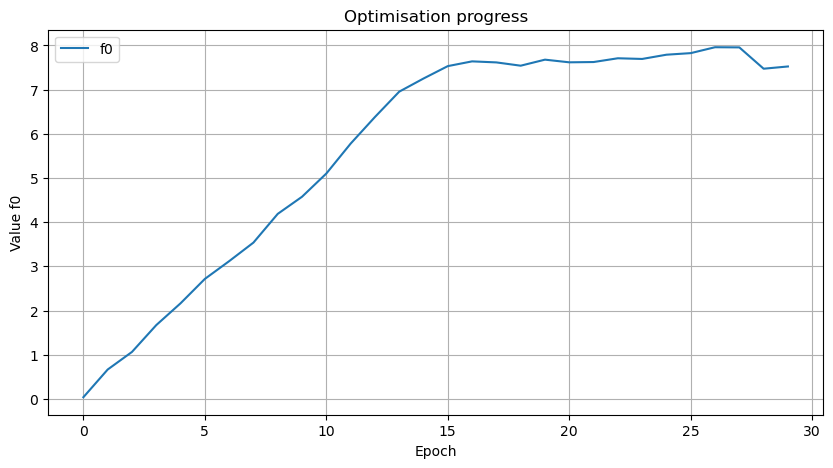

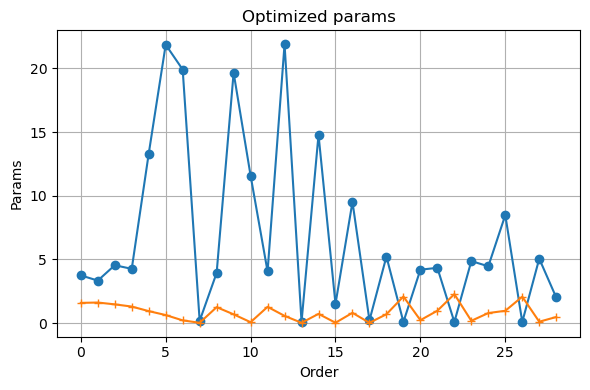

[Tensor] Saved NumPy array to ./global_a_params.npy
[Tensor] Saved Torch tensor to ./global_a_params.pt
[Tensor] Saved NumPy array to ./global_h_params.npy
[Tensor] Saved Torch tensor to ./global_h_params.pt
[INFO] История сохранена в loc_history.pkl


'loc_history.pkl'

In [11]:
# 0) Initial hyper params
loc_optimizer, store_loc_history, loc_u_a, loc_u_h = init_loc_opt_hyper(opt_zone_start, conf.loc_orders, a_initial=a_initial_params, h_initial=h_initial_params, p_min=p_min, p_max=p_max, lr=lr)

# 1) Begin optimization loop
loc_history, loc_best_a_params, loc_best_h_params  = run_loc_opt(opt_zone_start, conf.loc_orders, loc_optimizer, loc_u_a, loc_u_h, loc_history=store_loc_history, beta=beta)

# 2) Visualise 
viz_loc_opt(opt_zone_start, loc_history, loc_best_a_params,loc_best_h_params, conf.loc_orders, is_save=False)

# 3) Update global_params
update_global_params(opt_zone_start, global_a_params, global_h_params, loc_best_a_params, loc_best_h_params, is_save = True)

# 4) Save history
help_functions.save_history(loc_history, save=True)

### 3. TEST

### Utilities

In [8]:
global_a_params = torch.load("global_a_params.pt", weights_only=True)
global_h_params = torch.load("global_h_params.pt", weights_only=True)
# help_functions.save_history(loc_history, save=True, index=global_index_angle)
# for i in range (opt_zone_start, opt_zone_end):
#     test_loc_a = get_local_tensor_from_global(global_a_params, i, conf.loc_orders)
#     test_loc_h = get_local_tensor_from_global(global_h_params, i, conf.loc_orders)
#     print(f"тест области {i}, угол {angle_in_deg[i]} содержит элементов {len(test_loc_a)}")
#     test_loc(i, conf.loc_orders, stack_batch_src[i], test_loc_a, test_loc_h, is_plot_sim = False, is_smooth_mtf = True)

In [9]:
global_index_angle = 0
opt_zone_start = 0

тест области 0, угол 0.0 содержит элементов 118
len(rt) is 118
len(orders) is 117


FloatProgress(value=0.0, description='0% done ', max=200.0)

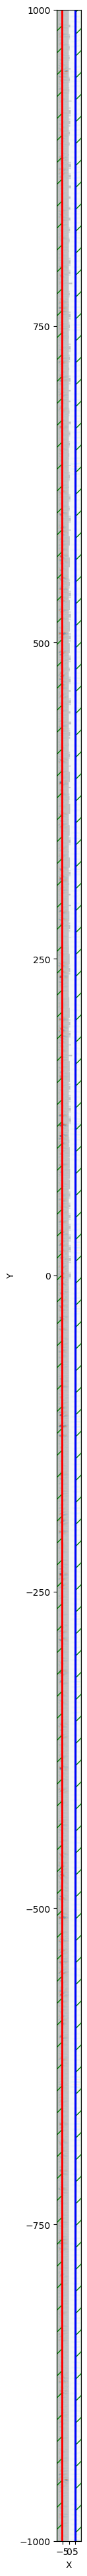

In [10]:
# print(f"тест области {opt_zone_start}, угол {angle_in_deg[opt_zone_start]} содержит элементов {len(global_a_params)}")
# IOptimized, IOptimized_base = test_loc(opt_zone_start, conf.loc_orders, stack_batch_src[opt_zone_start], global_a_params, global_h_params, is_plot_sim = True, is_smooth_mtf = False, intensity_mtf_ideal=IAiry_norm_scaled_in_angle_stack[global_index_angle])

print(f"тест области {opt_zone_start}, угол {angle_in_deg[opt_zone_start]} содержит элементов {len(global_a_params)}")
IOptimized = test_loc(opt_zone_start, conf.loc_orders, stack_batch_src[opt_zone_start], global_a_params, global_h_params, is_plot_sim = True)

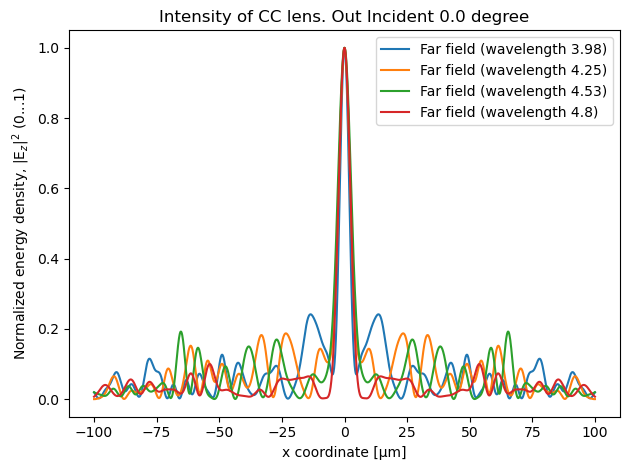

λ=3.98: FWHM = 4.50 µm
λ=4.25: FWHM = 5.50 µm
λ=4.53: FWHM = 6.30 µm
λ=4.8: FWHM = 5.50 µm


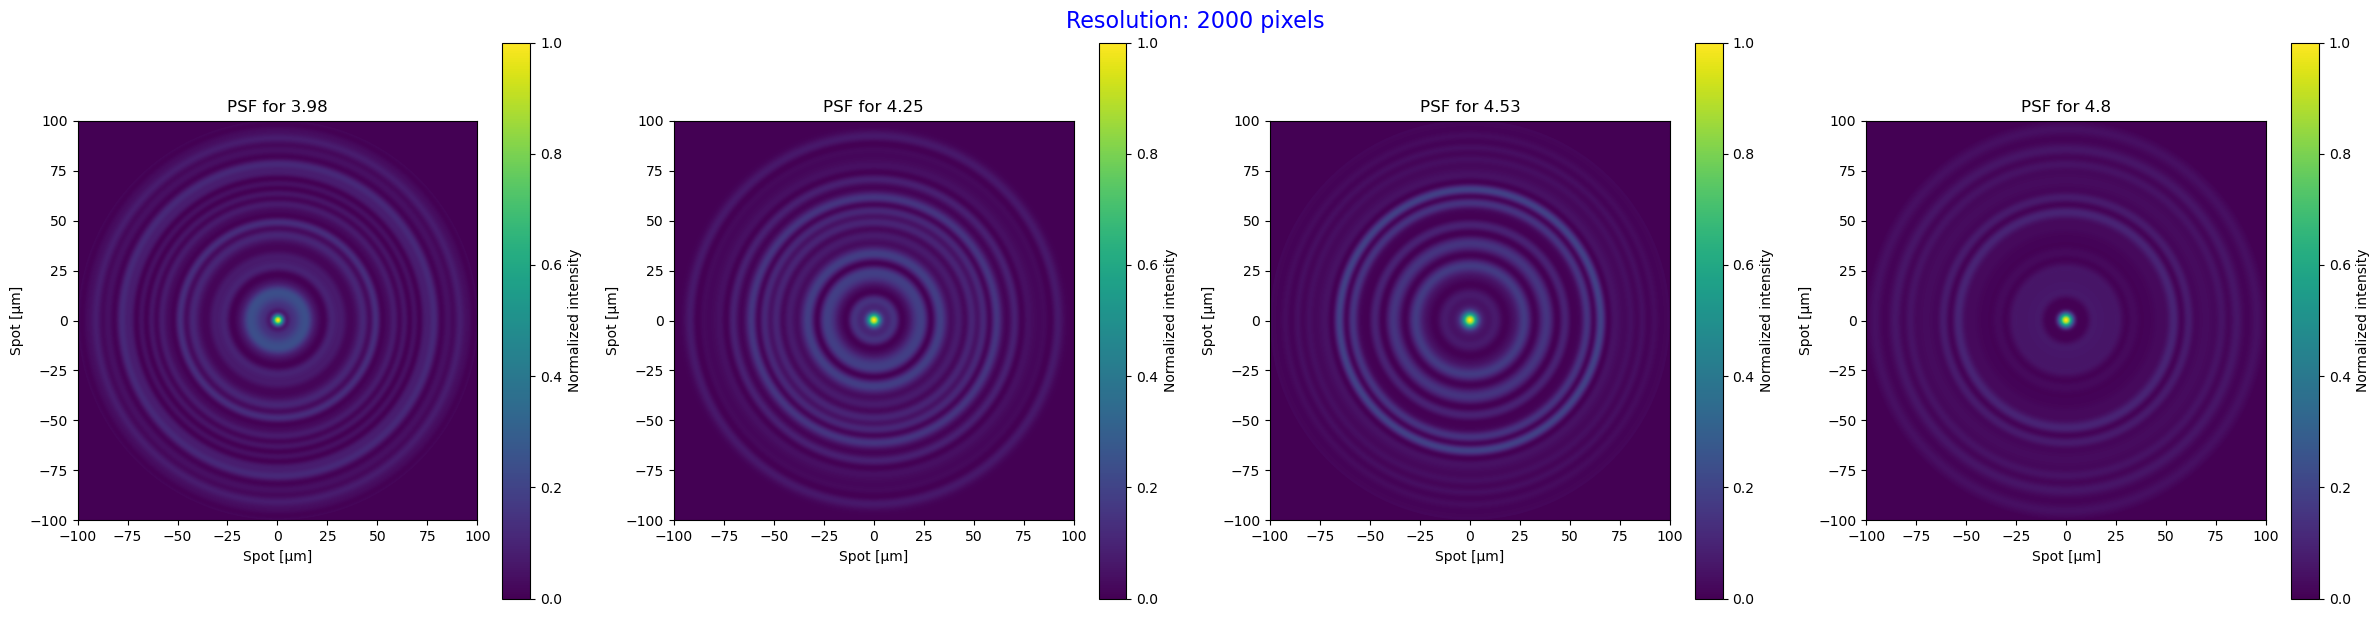

len of x = 2000
smooth x = 1001
smooth x = 1001
smooth x = 1001
smooth x = 1001


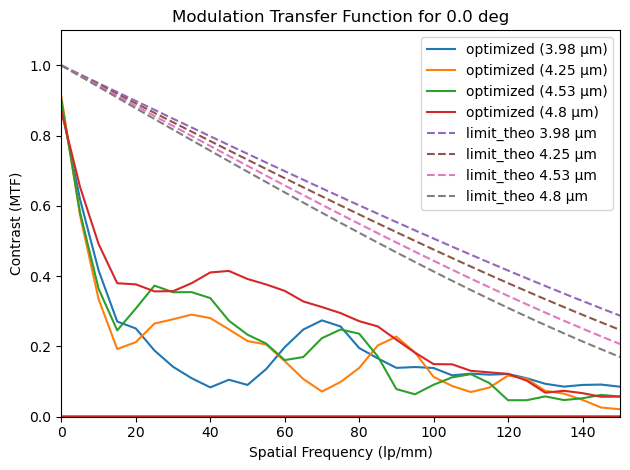

In [12]:
max_per_column = IOptimized.max(axis=0)
# max_per_column = max_IAiry_in_angle_stack[index_angle]
IOptimized_scaled = IOptimized / max_per_column

# Построение графиков выходных характеристик
nf.get_plot_intensity(
    IOptimized_scaled,
    out_angle_in_deg=angle_in_deg[opt_zone_start],
    wavelength_array=conf.inc_wavelength_array, shift = opt_zone_start * conf.diaphragm,
    isfwhm=True,
)
nf.plot_psf(
    conf.inc_nfreq-1, conf.spot_ff,
    IOptimized_scaled,
    out_angle_in_deg=angle_in_deg[opt_zone_start],
    shift = opt_zone_start * conf.diaphragm
)
nf.plot_mtf(
    conf.spot_ff, IOptimized_scaled,
    max_view=150,
    in_angle_in_deg=angle_after_refraction_in_deg[opt_zone_start],
    out_angle_in_deg=angle_in_deg[opt_zone_start],
    dif_lim=True, 
    smooth=True,
    I_mtf_theory = None,
)

In [13]:
# opt_efficiency_p = IOptimized.max(axis=0)/np.mean(IOptimized_base)
# print(f"opt_efficiency_p: {opt_efficiency_p}")
opt_efficiency_r = nf.get_focusing_efficiency(IOptimized/IOptimized.max(axis = 0), spot_ff=conf.spot_ff, out_angle_in_deg=0, shift=0)
print(f"opt_efficiency_r: {opt_efficiency_r}")
kpd = opt_efficiency_r/airy_efficiency_r
print(f"kpd: {kpd}")

opt_efficiency_r: [0.28045762 0.32979631 0.39823488 0.47522545]
kpd: [0.3173074  0.37246339 0.45037989 0.53761343]


In [14]:
np.mean(kpd)

0.41944102688752094

In [8]:
# nf.generate_lens_gds(global_a_params, conf.orders, rt_np, Q = conf.Q, w = conf.w, cell_name = 'LENS_CELL',)

GDS файл успешно сохранён: lens_layout.gds


In [17]:
mean_val = np.mean(kpd)          # среднее
var_val = np.var(kpd)            # дисперсия
std_val = np.std(kpd)            # стандартное отклонение

print("Среднее:", mean_val)
print("Дисперсия:", var_val)
print("Ст. отклонение:", std_val)

Среднее: 0.41944102688752094
Дисперсия: 0.006890026304031929
Ст. отклонение: 0.08300618232416143


In [18]:
kpd1 = [0.2005307, 0.12193318, 0.38550144, 0.76842823]

In [19]:
mean_val = np.mean(kpd1)          # среднее
var_val = np.var(kpd1)            # дисперсия
std_val = np.std(kpd1)            # стандартное отклонение

print("Среднее:", mean_val)
print("Дисперсия:", var_val)
print("Ст. отклонение:", std_val)

Среднее: 0.3690983875
Дисперсия: 0.062309772077502074
Ст. отклонение: 0.24961925422030665
